# Classical Baseline: TF-IDF + Logistic Regression for Complaint Category Classification

**Team project:** classify e-commerce customer-support complaints into 16 `Category` labels, two ways, compared head-to-head:

1. **Classical baseline** (this notebook) — TF-IDF (word counts) → Logistic Regression
2. **Transformer approach** (teammate's notebook) — pretrained sentence-transformer embeddings → the **same** Logistic Regression classifier

**Research question:** is the transformer's extra accuracy (if any) worth its extra compute cost, especially on rare/overlapping categories?

**Dataset:** `ecommerce_customer_support_cleaned.csv` — 1,334 complaints, 16 `Category` labels.

**Fairness rules used in this notebook (must match the transformer notebook exactly):**
- The exact same 80/20 stratified split as the transformer notebook — loaded from `shared_split/` rather than re-derived, to guarantee row-for-row identical train/test sets
- All 16 `Category` labels kept unmerged
- **Macro F1** is the primary metric (not accuracy)
- Compute cost (vectorization time, training time, inference latency, memory) is tracked alongside accuracy, for the final cost-vs-accuracy comparison


## 1. Imports

In [1]:
import time
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded.")


Libraries loaded.


## 2. Load Dataset

In [2]:
df = pd.read_csv('../data/ecommerce_customer_support_cleaned.csv')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head(3)


Shape: (1334, 3)
Columns: ['Complaint', 'Category', 'Urgency']


,Complaint,Category,Urgency
0,I can’t add a new address — button does nothing.,Account & Shipping,Low
1,Flash sale prices aren’t reflected during chec...,Promotions,Immediate
2,System declined my payment without any reason....,Payments,Immediate


## 3. Quick Sanity Check

(Full EDA is a teammate's part of the project — this is just enough to confirm the data matches spec: 16 categories, no nulls, no duplicates.)

In [3]:
print("Unique categories:", df['Category'].nunique())
print()
print("Category distribution:")
print(df['Category'].value_counts())
print()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())


Unique categories: 16

Category distribution:
Category
Promotions            137
Order Tracking        130
Payments              120
Shipping              108
Account               106
Product Quality       105
Special Requests      104
Inventory             103
Returns                99
Checkout               98
Subscriptions          97
Product Issues         29
Order Issues           29
Technical Issues       25
Account & Shipping     24
Refunds                20
Name: count, dtype: int64

Missing values:
 Complaint    0
Category     0
Urgency      0
dtype: int64
Duplicate rows: 0


## 4. Shared Train/Test Split

This notebook loads the **exact same split** used in the transformer notebook — the row indices saved to `shared_split/` — rather than re-deriving it independently. This removes any doubt about whether the two notebooks' splits actually line up, which matters since the whole comparison depends on both approaches being evaluated on identical held-out data.

In [4]:
train_idx = pd.read_csv('../data/shared_split/train_indices.csv')['index'].values
test_idx = pd.read_csv('../data/shared_split/test_indices.csv')['index'].values

X = df['Complaint'].astype(str).to_numpy(dtype=object)
y = df['Category'].astype(str).to_numpy(dtype=object)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Train size: {len(X_train)}")
print(f"Test size:  {len(X_test)}")
print("\n✓ Loaded the identical split used by the transformer notebook (shared_split/)")


Train size: 1067
Test size:  267

✓ Loaded the identical split used by the transformer notebook (shared_split/)


## 5. Classical Approach: TF-IDF

TF-IDF converts each complaint into a row of word-importance scores — common words score near zero, rare/distinctive words score higher. This is the "seen in course" feature-extraction method, contrasted with the transformer notebook's pretrained sentence-embeddings.

In [5]:
vectorize_start = time.time()

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

vectorize_time = time.time() - vectorize_start

vocab_size = len(vectorizer.vocabulary_)

print(f"Vectorization time (train+test, {len(X_train)+len(X_test)} texts): {vectorize_time:.3f}s")
print(f"Vocabulary size: {vocab_size}")
print(f"Train TF-IDF matrix shape: {X_train_tfidf.shape}")
print(f"Test TF-IDF matrix shape: {X_test_tfidf.shape}")


Vectorization time (train+test, 1334 texts): 0.040s
Vocabulary size: 1445
Train TF-IDF matrix shape: (1067, 1445)
Test TF-IDF matrix shape: (267, 1445)


## 6. Classifier: Logistic Regression

Same classifier family and settings as the transformer notebook — only the input features differ (TF-IDF counts here vs. embeddings there). This isolates the effect of the *feature representation*, which is the actual thing being studied.

We train two variants to address the class-imbalance research question:
- **Default** — standard Logistic Regression
- **Balanced** — `class_weight='balanced'`, which up-weights rare categories during training

In [6]:
results = {}

for variant, weight in [('default', None), ('balanced', 'balanced')]:
    train_start = time.time()
    clf = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
        class_weight=weight
    )
    clf.fit(X_train_tfidf, y_train)
    train_time = time.time() - train_start

    infer_start = time.time()
    y_pred = clf.predict(X_test_tfidf)
    infer_time = time.time() - infer_start
    infer_latency_ms = (infer_time / X_test_tfidf.shape[0]) * 1000

    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    acc = accuracy_score(y_test, y_pred)

    results[variant] = {
        'model': clf,
        'y_pred': y_pred,
        'train_time_s': train_time,
        'infer_latency_ms_per_sample': infer_latency_ms,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'accuracy': acc,
    }

    print(f"--- {variant} ---")
    print(f"  Train time: {train_time:.3f}s")
    print(f"  Inference latency: {infer_latency_ms:.4f} ms/sample")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Macro F1: {macro_f1:.4f}   (primary metric)")
    print(f"  Weighted F1: {weighted_f1:.4f}")
    print()


--- default ---
  Train time: 0.094s
  Inference latency: 0.0037 ms/sample
  Accuracy: 0.8277
  Macro F1: 0.7693   (primary metric)
  Weighted F1: 0.8186



--- balanced ---
  Train time: 0.056s
  Inference latency: 0.0008 ms/sample
  Accuracy: 0.8614
  Macro F1: 0.8659   (primary metric)
  Weighted F1: 0.8589



In [7]:
# Interpretation
d, b = results['default'], results['balanced']
delta = b['macro_f1'] - d['macro_f1']
pct_change = (delta / d['macro_f1']) * 100

print(
    f"Macro F1 went from {d['macro_f1']:.3f} (default) to {b['macro_f1']:.3f} (balanced), "
    f"a {'gain' if delta >= 0 else 'drop'} of {abs(pct_change):.1f}%.\n"
    f"As with the transformer approach, class weighting mainly affects performance on rare "
    f"categories rather than the model's overall speed or size."
)


Macro F1 went from 0.769 (default) to 0.866 (balanced), a gain of 12.6%.
As with the transformer approach, class weighting mainly affects performance on rare categories rather than the model's overall speed or size.


## 7. Detailed Evaluation (Balanced Variant)

In [8]:
best_variant = 'balanced'
y_pred = results[best_variant]['y_pred']

print(f"Classification Report — {best_variant} Logistic Regression on TF-IDF features\n")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report — balanced Logistic Regression on TF-IDF features

                    precision    recall  f1-score   support

           Account       0.91      1.00      0.95        21
Account & Shipping       0.71      1.00      0.83         5
          Checkout       0.83      0.53      0.65        19
         Inventory       0.83      0.90      0.86        21
      Order Issues       0.71      0.83      0.77         6
    Order Tracking       0.95      0.73      0.83        26
          Payments       0.79      0.79      0.79        24
    Product Issues       1.00      1.00      1.00         6
   Product Quality       0.90      0.90      0.90        21
        Promotions       0.93      0.93      0.93        27
           Refunds       1.00      0.75      0.86         4
           Returns       0.86      0.95      0.90        20
          Shipping       0.70      0.86      0.78        22
  Special Requests       0.83      0.95      0.89        21
     Subscriptions       1

In [9]:
# Interpretation
report_dict = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
per_class = {k: v for k, v in report_dict.items() if k in df['Category'].unique()}
best_class = max(per_class, key=lambda k: per_class[k]['f1-score'])
worst_class = min(per_class, key=lambda k: per_class[k]['f1-score'])

print(
    f"Best-performing category: '{best_class}' (F1 = {per_class[best_class]['f1-score']:.3f}, "
    f"support = {int(per_class[best_class]['support'])}).\n"
    f"Worst-performing category: '{worst_class}' (F1 = {per_class[worst_class]['f1-score']:.3f}, "
    f"support = {int(per_class[worst_class]['support'])}).\n"
    f"Overall accuracy is {report_dict['accuracy']:.3f}, but macro F1 "
    f"({report_dict['macro avg']['f1-score']:.3f}) is what we report as primary."
)


Best-performing category: 'Product Issues' (F1 = 1.000, support = 6).
Worst-performing category: 'Checkout' (F1 = 0.645, support = 19).
Overall accuracy is 0.861, but macro F1 (0.866) is what we report as primary.


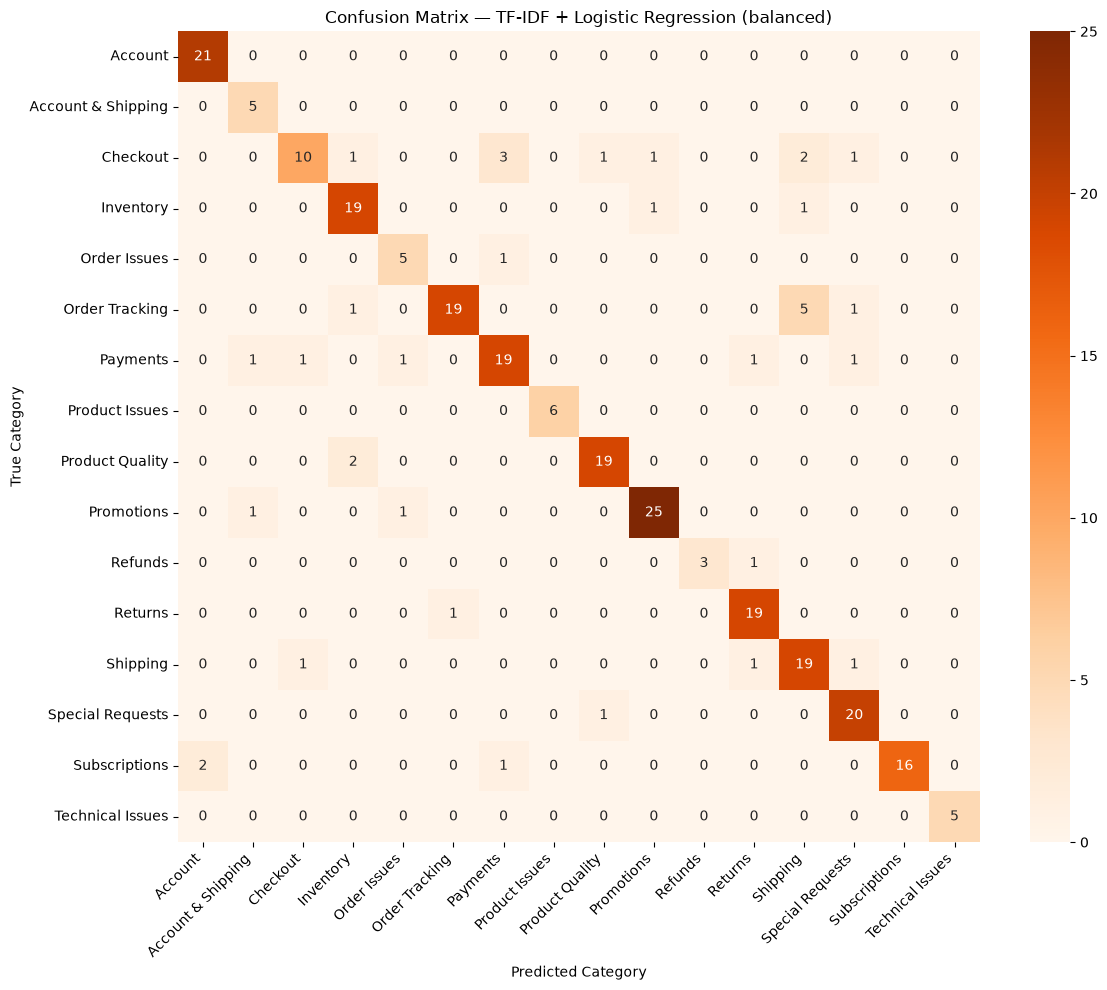

In [10]:
labels_sorted = sorted(df['Category'].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.title(f'Confusion Matrix — TF-IDF + Logistic Regression ({best_variant})')
plt.ylabel('True Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 8. Class Imbalance: Default vs Balanced

Comparing per-class F1 for the two classifier variants — same analysis as the transformer notebook, for direct comparison.

                     default  balanced  support
Refunds             0.400000  0.857143       20
Account & Shipping  0.333333  0.833333       24
Technical Issues    0.888889  1.000000       25
Order Issues        0.666667  0.769231       29
Product Issues      0.800000  1.000000       29
Subscriptions       0.914286  0.914286       97
Checkout            0.625000  0.645161       98
Returns             0.904762  0.904762       99
Inventory           0.837209  0.863636      103
Special Requests    0.888889  0.888889      104
Product Quality     0.904762  0.904762      105
Account             0.930233  0.954545      106
Shipping            0.730769  0.775510      108
Payments            0.823529  0.791667      120
Order Tracking      0.745098  0.826087      130
Promotions          0.915254  0.925926      137


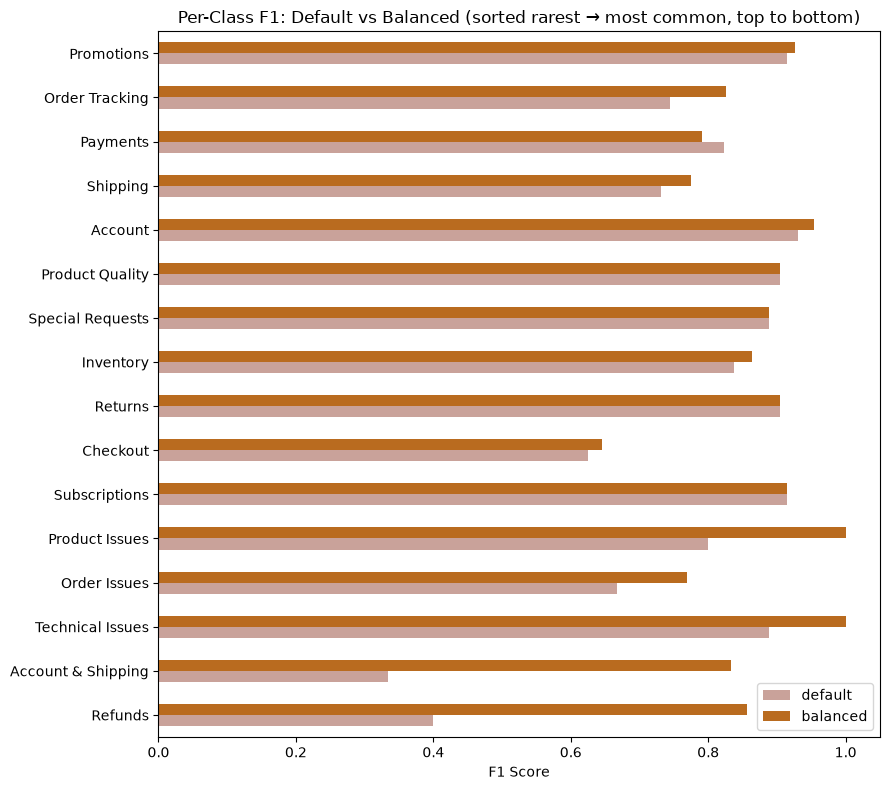

In [11]:
per_class_f1 = pd.DataFrame({
    'default': f1_score(y_test, results['default']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
    'balanced': f1_score(y_test, results['balanced']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
}, index=labels_sorted)

category_counts = df['Category'].value_counts()
per_class_f1['support'] = category_counts.reindex(labels_sorted).values
per_class_f1 = per_class_f1.sort_values('support')

print(per_class_f1)

per_class_f1[['default', 'balanced']].plot(
    kind='barh', figsize=(9, 8), color=['#C9A29A', '#B96B1F']
)
plt.title('Per-Class F1: Default vs Balanced (sorted rarest → most common, top to bottom)')
plt.xlabel('F1 Score')
plt.tight_layout()
plt.show()


In [12]:
# Interpretation
per_class_f1['improvement'] = per_class_f1['balanced'] - per_class_f1['default']
rare_only = per_class_f1[per_class_f1['support'] < 30]
common_only = per_class_f1[per_class_f1['support'] >= 30]

print(
    f"Among the rare categories (< 30 examples: {', '.join(rare_only.index)}), "
    f"'balanced' changes F1 by {rare_only['improvement'].mean():+.3f} on average.\n"
    f"Among the common categories (>= 30 examples), 'balanced' changes F1 by "
    f"{common_only['improvement'].mean():+.3f} on average."
)


Among the rare categories (< 30 examples: Refunds, Account & Shipping, Technical Issues, Order Issues, Product Issues), 'balanced' changes F1 by +0.274 on average.
Among the common categories (>= 30 examples), 'balanced' changes F1 by +0.016 on average.


## 9. Error Analysis

Inspecting misclassified complaints — especially for rare categories.

In [13]:
errors_df = pd.DataFrame({
    'Complaint': X_test,
    'True Category': y_test,
    'Predicted Category': y_pred,
})
errors_df = errors_df[errors_df['True Category'] != errors_df['Predicted Category']]

print(f"Total misclassifications: {len(errors_df)} out of {len(X_test)} test samples "
      f"({len(errors_df)/len(X_test)*100:.1f}%)")
print()

rare_categories = category_counts[category_counts < 30].index.tolist()
print("Rare categories (< 30 examples total):", rare_categories)
print()

rare_errors = errors_df[
    errors_df['True Category'].isin(rare_categories) |
    errors_df['Predicted Category'].isin(rare_categories)
]
pd.set_option('display.max_colwidth', 80)
rare_errors.head(15)


Total misclassifications: 37 out of 267 test samples (13.9%)

Rare categories (< 30 examples total): ['Product Issues', 'Order Issues', 'Technical Issues', 'Account & Shipping', 'Refunds']



,Complaint,True Category,Predicted Category
96,I clicked on a 15% off ad and it vanished at checkout. — this is very frustr...,Promotions,Account & Shipping
115,Used Apple Pay — no order confirmation received. please fix this ASAP,Payments,Order Issues
160,I got charged but no confirmation email came through. and I don't know what ...,Order Issues,Payments
195,System declined my payment without any reason. — this is very frustrating,Payments,Account & Shipping
204,I never received the promised sign-up bonus. please fix this ASAP,Promotions,Order Issues
263,Still waiting for confirmation that my refund is being processed. which is u...,Refunds,Returns


## 10. Cost Summary

The lightweight side of the comparison — no neural network, no pretrained model, just word counts and a linear classifier.

In [14]:
cost_summary = pd.DataFrame({
    'Metric': [
        'Vocabulary size (unique words)',
        'Vectorization time — all data (s)',
        'Avg. vectorization time per text (ms)',
        'Classifier training time — balanced (s)',
        'Inference latency — balanced (ms/sample)',
    ],
    'Value': [
        f"{vocab_size:,}",
        f"{vectorize_time:.3f}",
        f"{(vectorize_time / (len(X_train) + len(X_test))) * 1000:.3f}",
        f"{results['balanced']['train_time_s']:.3f}",
        f"{results['balanced']['infer_latency_ms_per_sample']:.4f}",
    ]
})
cost_summary


,Metric,Value
0,Vocabulary size (unique words),"1,445"
1,Vectorization time — all data (s),0.040
2,Avg. vectorization time per text (ms),0.030
3,Classifier training time — balanced (s),0.056
4,Inference latency — balanced (ms/sample),0.0008


## 11. Save Artifacts (for team comparison + reuse)

In [15]:
os.makedirs('../artifacts', exist_ok=True)

with open('../artifacts/logreg_tfidf_balanced.pickle', 'wb') as f:
    pickle.dump(results['balanced']['model'], f)

with open('../artifacts/tfidf_vectorizer.pickle', 'wb') as f:
    pickle.dump(vectorizer, f)

metrics_out = {
    'approach': 'tfidf_logreg_baseline',
    'feature_method': 'TfidfVectorizer',
    'classifier': 'LogisticRegression',
    'random_state': RANDOM_STATE,
    'test_size': 0.2,
    'default': {k: v for k, v in results['default'].items() if k not in ('model', 'y_pred')},
    'balanced': {k: v for k, v in results['balanced'].items() if k not in ('model', 'y_pred')},
    'cost': {
        'vocab_size': vocab_size,
        'vectorize_time_s': vectorize_time,
    }
}
with open('../artifacts/baseline_metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=2)

print("✓ Classifier saved to artifacts/logreg_tfidf_balanced.pickle")
print("✓ Metrics saved to artifacts/baseline_metrics.json (share this with your teammates)")


✓ Classifier saved to artifacts/logreg_tfidf_balanced.pickle
✓ Metrics saved to artifacts/baseline_metrics.json (share this with your teammates)


## 12. Conclusion (Classical Baseline)

- **Macro F1 achieved:** see Section 6/7 output above — this is the number to compare against the transformer approach's macro F1 on the *same* test split (loaded from `shared_split/`, guaranteeing a fair comparison).
- **Class imbalance:** Section 8 shows whether `class_weight='balanced'` meaningfully helps rare categories without hurting common ones, for this classical approach.
- **Cost:** Section 10 quantifies the lightweight footprint of this approach — no pretrained model, no neural network, just TF-IDF word counts.
- **Next step for the team:** combine this notebook's `artifacts/baseline_metrics.json` with the transformer notebook's `artifacts/transformer_metrics.json` to answer the project's core research question — is the transformer's accuracy gain (if any) worth its extra compute cost?
